In [ ]:

# GreenGrid Big Data Project
# Step 1: Check the Colab environment

import os
import sys
import platform

print("===== ENVIRONMENT INFORMATION =====")
print("Python Version:", sys.version)
print("Operating System:", platform.platform())
print("Current Directory:", os.getcwd())

print("\n===== JAVA CHECK =====")
!java -version

print("\n===== STORAGE CHECK =====")
!df -h /


===== ENVIRONMENT INFORMATION =====
Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Operating System: Linux-6.6.159+-x86_64-with-glibc2.39
Current Directory: /content

===== JAVA CHECK =====
[0.035s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.035s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)

===== STORAGE CHECK =====
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   85M  108G   1% /


In [ ]:

# Step 2: Install Java 17

!apt-get update -qq
!apt-get install -y openjdk-17-jdk-headless

# Configure Java 17 for this notebook session
import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

# Verify installation
!java -version
!echo $JAVA_HOME


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  openjdk-17-jre-headless
Suggested packages:
  openjdk-17-demo openjdk-17-source libnss-mdns fonts-dejavu-extra
  fonts-ipafont-gothic fonts-ipafont-mincho fonts-wqy-microhei
  | fonts-wqy-zenhei fonts-indic
The following NEW packages will be installed:
  openjdk-17-jdk-headless openjdk-17-jre-headless
0 upgraded, 2 newly installed, 0 to remove and 10 not upgraded.
Need to get 120 MB of archives.
After this operation, 272 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 openjdk-17-jre-headless amd64 17.0.20.1+1-1~24.04 [48.1 MB]
Get:2 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 open

In [ ]:

# Step 3: Download and extract Apache Hadoop 3.5.0

import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

%cd /content

!wget -q https://downloads.apache.org/hadoop/common/hadoop-3.5.0/hadoop-3.5.0.tar.gz

# Extract Hadoop
!tar -xzf hadoop-3.5.0.tar.gz

# Rename folder for convenience
!mv hadoop-3.5.0 hadoop

# Verify downloaded files
!ls -lh /content/hadoop


/content
total 124K
drwxr-xr-x 2 1001 1002 4.0K Mar 24  2026 bin
drwxr-xr-x 3 1001 1002 4.0K Mar 24  2026 compose
-rw-r--r-- 1 1001 1002  933 Mar 24  2026 Dockerfile
drwxr-xr-x 3 1001 1002 4.0K Mar 24  2026 etc
drwxr-xr-x 2 1001 1002 4.0K Mar 24  2026 include
drwxr-xr-x 3 1001 1002 4.0K Mar 24  2026 lib
drwxr-xr-x 4 1001 1002 4.0K Mar 24  2026 libexec
-rw-rw-r-- 1 1001 1002  29K Mar 24  2026 LICENSE-binary
drwxr-xr-x 2 1001 1002 4.0K Mar 24  2026 licenses-binary
-rw-rw-r-- 1 1001 1002  16K Feb 24  2026 LICENSE.txt
-rw-rw-r-- 1 1001 1002  27K Feb 24  2026 NOTICE-binary
-rw-rw-r-- 1 1001 1002 1.6K Feb 24  2026 NOTICE.txt
-rw-rw-r-- 1 1001 1002  175 Feb 24  2026 README.txt
drwxr-xr-x 3 1001 1002 4.0K Mar 24  2026 sbin
drwxr-xr-x 4 1001 1002 4.0K Mar 24  2026 share


In [ ]:

# Configure Hadoop environment

import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["HADOOP_HOME"] = "/content/hadoop"
os.environ["PATH"] = (
    "/content/hadoop/bin:/content/hadoop/sbin:"
    + os.environ["PATH"]
)

# Verify Hadoop installation
!hadoop version


Hadoop 3.5.0
Source code repository https://github.com/apache/hadoop.git -r dbcc7cd797100e6b32cd84f85b53a5193a5f9af0
Compiled by cnauroth on 2026-03-24T16:56Z
Compiled on platform linux-x86_64
Compiled with protoc 3.25.5
From source with checksum 64582ed0a62a169c39a19c734a8f33b5
This command was run using /content/hadoop/share/hadoop/common/hadoop-common-3.5.0.jar


In [ ]:

import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["HADOOP_HOME"] = "/content/hadoop"
os.environ["HADOOP_CONF_DIR"] = "/content/hadoop/etc/hadoop"

os.environ["PATH"] = (
    "/content/hadoop/bin:/content/hadoop/sbin:"
    + os.environ["PATH"]
)

print("JAVA_HOME:", os.environ["JAVA_HOME"])
print("HADOOP_HOME:", os.environ["HADOOP_HOME"])
print("HADOOP_CONF_DIR:", os.environ["HADOOP_CONF_DIR"])


JAVA_HOME: /usr/lib/jvm/java-17-openjdk-amd64
HADOOP_HOME: /content/hadoop
HADOOP_CONF_DIR: /content/hadoop/etc/hadoop


In [ ]:

%%writefile /content/hadoop/etc/hadoop/core-site.xml
<?xml version="1.0" encoding="UTF-8"?>
<?xml-stylesheet type="text/xsl" href="configuration.xsl"?>

<configuration>
    <property>
        <name>fs.defaultFS</name>
        <value>hdfs://localhost:9000</value>
    </property>
</configuration>


Overwriting /content/hadoop/etc/hadoop/core-site.xml


In [ ]:

%%writefile /content/hadoop/etc/hadoop/hdfs-site.xml
<?xml version="1.0" encoding="UTF-8"?>
<?xml-stylesheet type="text/xsl" href="configuration.xsl"?>

<configuration>
    <property>
        <name>dfs.replication</name>
        <value>1</value>
    </property>

    <property>
        <name>dfs.namenode.name.dir</name>
        <value>file:///content/hadoop_data/namenode</value>
    </property>

    <property>
        <name>dfs.datanode.data.dir</name>
        <value>file:///content/hadoop_data/datanode</value>
    </property>

    <property>
        <name>dfs.namenode.rpc-address</name>
        <value>localhost:9000</value>
    </property>

    <property>
        <name>dfs.namenode.http-address</name>
        <value>0.0.0.0:9870</value>
    </property>
</configuration>


Overwriting /content/hadoop/etc/hadoop/hdfs-site.xml


In [ ]:

!mkdir -p /content/hadoop_data/namenode
!mkdir -p /content/hadoop_data/datanode

print("Hadoop storage directories created.")


Hadoop storage directories created.


In [ ]:

!hdfs namenode -format


2026-11-03 04:28:40,974 INFO namenode.NameNode: STARTUP_MSG: 
/************************************************************
STARTUP_MSG: Starting NameNode
STARTUP_MSG:   host = 3fa1e404d793/172.28.0.12
STARTUP_MSG:   args = [-format]
STARTUP_MSG:   version = 3.5.0
STARTUP_MSG:   classpath = /content/hadoop/etc/hadoop:/content/hadoop/share/hadoop/common/lib/jetty-io-9.4.58.v20250814.jar:/content/hadoop/share/hadoop/common/lib/re2j-1.1.jar:/content/hadoop/share/hadoop/common/lib/commons-collections4-4.4.jar:/content/hadoop/share/hadoop/common/lib/hk2-api-2.6.1.jar:/content/hadoop/share/hadoop/common/lib/jersey-server-2.46.jar:/content/hadoop/share/hadoop/common/lib/httpclient-4.5.13.jar:/content/hadoop/share/hadoop/common/lib/jetty-util-ajax-9.4.58.v20250814.jar:/content/hadoop/share/hadoop/common/lib/curator-recipes-5.2.0.jar:/content/hadoop/share/hadoop/common/lib/snappy-java-1.1.10.4.jar:/content/hadoop/share/hadoop/common/lib/audience-annotations-0.12.0.jar:/content/hadoop/share/hado

In [ ]:

# Start Hadoop NameNode

!hdfs --daemon start namenode

print("NameNode startup command executed.")


NameNode startup command executed.


In [ ]:

# Start Hadoop DataNode

!hdfs --daemon start datanode

print("DataNode startup command executed.")


DataNode startup command executed.


In [ ]:

# Check running Hadoop processes

!jps


6422 DataNode
6331 NameNode
6623 Jps


In [ ]:

# Check HDFS filesystem status

!hdfs dfsadmin -report


Configured Capacity: 115658190848 (107.72 GB)
Present Capacity: 113287053312 (105.51 GB)
DFS Remaining: 113287028736 (105.51 GB)
DFS Used: 24576 (24 KB)
DFS Used%: 0.00%
Replicated Blocks:
	Under replicated blocks: 0
	Blocks with corrupt replicas: 0
	Missing blocks: 0
	Missing blocks (with replication factor 1): 0
	Badly Distributed Blocks: 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0
Erasure Coded Block Groups: 
	Low redundancy block groups: 0
	Block groups with corrupt internal blocks: 0
	Missing block groups: 0
	Badly Distributed Blocks: 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0

-------------------------------------------------
Live datanodes (1):

Name: 127.0.0.1:9866 (localhost)
Hostname: 3fa1e404d793
Decommission Status : Normal
Configured Capacity: 115658190848 (107.72 GB)
DFS Used: 24576 (24 KB)
Non DFS Used: 2354360320 (2.19 GB)
DFS Remaining: 113287028736 (105.51 GB)
DFS Used%: 0.00%
D

In [ ]:

# Create project directories in HDFS

!hdfs dfs -mkdir -p /greengrid/input
!hdfs dfs -mkdir -p /greengrid/output
!hdfs dfs -mkdir -p /greengrid/analytics

# Display directory structure
!hdfs dfs -ls -R /greengrid


drwxr-xr-x   - root supergroup          0 2026-11-03 04:30 /greengrid/analytics
drwxr-xr-x   - root supergroup          0 2026-11-03 04:29 /greengrid/input
drwxr-xr-x   - root supergroup          0 2026-11-03 04:29 /greengrid/output


In [ ]:

# Upload training dataset to HDFS

!hdfs dfs -put /content/train.csv /greengrid/input/

print("Training dataset uploaded successfully!")


Training dataset uploaded successfully!


In [ ]:

# Upload testing dataset to HDFS

!hdfs dfs -put /content/test.csv /greengrid/input/

print("Testing dataset uploaded successfully!")


Testing dataset uploaded successfully!


In [ ]:

# List files stored in HDFS

!hdfs dfs -ls -h /greengrid/input


Found 2 items
-rw-r--r--   1 root supergroup      2.1 M 2026-11-03 04:33 /greengrid/input/test.csv
-rw-r--r--   1 root supergroup      9.2 M 2026-11-03 04:32 /greengrid/input/train.csv


In [ ]:

# Read first 5 lines from HDFS training dataset

!hdfs dfs -cat /greengrid/input/train.csv | head -5


row_id,household_id,date,num_residents,home_sqft,has_ev,has_solar,has_pool,heating_type,hvac_age_years,temp_avg_c,temp_min_c,temp_max_c,humidity_pct,wind_kph,precip_mm,solar_index,is_weekend,is_holiday,prior_day_kwh,prior_week_avg_kwh,kwh
0,H00000,2025-01-02,4,1654,0,0,0,electric,25,-6.5,-11.0,-2.0,70,12.9,0.0,7.4,0,0,29.11,29.11,32.91
1,H00000,2025-01-03,4,1654,0,0,0,electric,25,-6.5,-9.0,-3.9,37,10.1,0.0,6.3,0,0,32.91,31.009999999999998,27.97
2,H00000,2025-01-04,4,1654,0,0,0,electric,25,-6.7,-9.0,-4.5,92,9.9,0.0,7.2,1,0,27.97,29.996666666666666,30.81
3,H00000,2025-01-05,4,1654,0,0,0,electric,25,-7.0,-11.0,-3.1,65,15.1,0.0,3.3,1,0,30.81,30.2,32.56
cat: Unable to write to output stream.


In [ ]:

# Check HDFS storage usage

!hdfs dfs -du -h /greengrid/input

# Check total HDFS storage
!hdfs dfs -count -h /greengrid


2.1 M  2.1 M  /greengrid/input/test.csv
9.2 M  9.2 M  /greengrid/input/train.csv
           4            2             11.3 M /greengrid


In [ ]:

# GREEN GRID PROJECT - STEP 1
# Upload datasets into Hadoop HDFS

import os
import pandas as pd

# Configure Hadoop
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["HADOOP_HOME"] = "/content/hadoop"
os.environ["PATH"] = "/content/hadoop/bin:/content/hadoop/sbin:" + os.environ["PATH"]

# Check local datasets
train_path = "/content/train.csv"
test_path = "/content/test.csv"

assert os.path.exists(train_path), "train.csv not found!"
assert os.path.exists(test_path), "test.csv not found!"

# Read datasets
train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print("TRAINING DATA:", train.shape)
print("TESTING DATA:", test.shape)

print("\nCOLUMNS:")
print(train.columns.tolist())

# Upload to HDFS (safe to rerun)
!hdfs dfs -mkdir -p /greengrid/input
!hdfs dfs -rm -f /greengrid/input/train.csv
!hdfs dfs -rm -f /greengrid/input/test.csv

!hdfs dfs -put /content/train.csv /greengrid/input/
!hdfs dfs -put /content/test.csv /greengrid/input/

print("\nHDFS DATASET VERIFICATION:")
!hdfs dfs -ls -h /greengrid/input

print("\nDATASET UPLOAD COMPLETED!")


TRAINING DATA: (88500, 22)
TESTING DATA: (21000, 21)

COLUMNS:
['row_id', 'household_id', 'date', 'num_residents', 'home_sqft', 'has_ev', 'has_solar', 'has_pool', 'heating_type', 'hvac_age_years', 'temp_avg_c', 'temp_min_c', 'temp_max_c', 'humidity_pct', 'wind_kph', 'precip_mm', 'solar_index', 'is_weekend', 'is_holiday', 'prior_day_kwh', 'prior_week_avg_kwh', 'kwh']
Deleted /greengrid/input/train.csv
Deleted /greengrid/input/test.csv

HDFS DATASET VERIFICATION:
Found 2 items
-rw-r--r--   1 root supergroup      2.1 M 2026-11-03 04:36 /greengrid/input/test.csv
-rw-r--r--   1 root supergroup      9.2 M 2026-11-03 04:36 /greengrid/input/train.csv

DATASET UPLOAD COMPLETED!


In [ ]:

# GREEN GRID PROJECT - STEP 2
# Data cleaning and preprocessing

import pandas as pd
import numpy as np

train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")

# Remove duplicate records
train = train.drop_duplicates()
test = test.drop_duplicates()

# Convert date column
train["date"] = pd.to_datetime(train["date"], errors="coerce")
test["date"] = pd.to_datetime(test["date"], errors="coerce")

# Remove invalid dates
train = train.dropna(subset=["date", "kwh"])

# Handle missing numerical values
for df in [train, test]:
    numeric_cols = df.select_dtypes(include=np.number).columns
    for col in numeric_cols:
        df[col] = df[col].fillna(df[col].median())

    categorical_cols = df.select_dtypes(include="object").columns
    for col in categorical_cols:
        if df[col].isna().any():
            df[col] = df[col].fillna(df[col].mode()[0])

print("CLEANING COMPLETED")
print("Training shape:", train.shape)
print("Testing shape:", test.shape)

print("\nMissing values in training:", train.isnull().sum().sum())
print("Missing values in testing:", test.isnull().sum().sum())

# Save cleaned datasets
train.to_csv("/content/clean_train.csv", index=False)
test.to_csv("/content/clean_test.csv", index=False)

# Upload cleaned training data to HDFS
!hdfs dfs -mkdir -p /greengrid/cleaned
!hdfs dfs -put -f /content/clean_train.csv /greengrid/cleaned/

print("\nCleaned training data uploaded to HDFS.")


CLEANING COMPLETED
Training shape: (88500, 22)
Testing shape: (21000, 21)

Missing values in training: 0
Missing values in testing: 0

Cleaned training data uploaded to HDFS.


In [ ]:

# ============================================================
# GREENGRID PROJECT
# STEP 3: HADOOP MAPREDUCE IMPLEMENTATION
# Three real Hadoop Streaming jobs
# ============================================================

import os
import glob
import subprocess
import pandas as pd

# 1. Configure Hadoop
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["HADOOP_HOME"] = "/content/hadoop"
os.environ["PATH"] = (
    "/content/hadoop/bin:/content/hadoop/sbin:" + os.environ["PATH"]
)

# 2. Load cleaned dataset
data_path = "/content/clean_train.csv"

if not os.path.exists(data_path):
    data_path = "/content/train.csv"

df = pd.read_csv(data_path)

required = ["household_id", "date", "heating_type", "kwh"]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["kwh"] = pd.to_numeric(df["kwh"], errors="coerce")
df = df.dropna(subset=required)

print("Dataset loaded:", df.shape)

# 3. Ensure Hadoop services are running
processes = subprocess.getoutput("jps")
print("\nHadoop processes:\n", processes)

if "NameNode" not in processes:
    subprocess.run(["hdfs", "--daemon", "start", "namenode"], check=True)

if "DataNode" not in processes:
    subprocess.run(["hdfs", "--daemon", "start", "datanode"], check=True)

# 4. Locate Hadoop Streaming JAR
jars = glob.glob(
    "/content/hadoop/share/hadoop/tools/lib/hadoop-streaming*.jar"
)

if not jars:
    raise FileNotFoundError("Hadoop Streaming JAR not found.")

STREAMING_JAR = jars[0]
print("\nStreaming JAR:", STREAMING_JAR)

# 5. Create Mapper script
mapper_code = r'''#!/usr/bin/env python3
import sys

for line in sys.stdin:
    line = line.rstrip("\n")
    parts = line.split("\t", 1)

    if len(parts) == 2:
        key, value = parts
        try:
            print(f"{key}\t{float(value)}")
        except ValueError:
            continue
'''

with open("/content/mapper.py", "w") as f:
    f.write(mapper_code)

# 6. Create Reducer script
reducer_code = r'''#!/usr/bin/env python3
import sys

current_key = None
total = 0.0
count = 0

def emit(key, total, count):
    if key is not None and count > 0:
        print(f"{key}\t{total/count:.4f}\t{count}")

for line in sys.stdin:
    parts = line.rstrip("\n").split("\t")

    if len(parts) != 2:
        continue

    key, value = parts

    try:
        value = float(value)
    except ValueError:
        continue

    if key != current_key:
        emit(current_key, total, count)
        current_key = key
        total = 0.0
        count = 0

    total += value
    count += 1

emit(current_key, total, count)
'''

with open("/content/reducer.py", "w") as f:
    f.write(reducer_code)

os.chmod("/content/mapper.py", 0o755)
os.chmod("/content/reducer.py", 0o755)

# 7. Prepare Hadoop input datasets
jobs = {
    "household": "household_id",
    "daily": "date",
    "heating": "heating_type"
}

for job, column in jobs.items():

    local_file = f"/content/{job}_input.tsv"

    temp = df[[column, "kwh"]].copy()
    temp[column] = temp[column].astype(str)
    temp["kwh"] = pd.to_numeric(temp["kwh"], errors="coerce")
    temp = temp.dropna()

    temp.to_csv(
        local_file,
        sep="\t",
        index=False,
        header=False
    )

    hdfs_input = f"/greengrid/mapreduce/input/{job}"
    hdfs_output = f"/greengrid/mapreduce/output/{job}"

    subprocess.run(
        ["hdfs", "dfs", "-mkdir", "-p", hdfs_input],
        check=True
    )

    subprocess.run(
        ["hdfs", "dfs", "-put", "-f", local_file, hdfs_input + "/"],
        check=True
    )

    # Remove previous output if rerunning
    subprocess.run(
        ["hdfs", "dfs", "-rm", "-r", "-f", hdfs_output],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )

    # 8. Execute genuine Hadoop Streaming MapReduce
    command = [
        "hadoop", "jar", STREAMING_JAR,
        "-D", "mapreduce.job.reduces=1",
        "-files", "/content/mapper.py,/content/reducer.py",
        "-mapper", "python3 mapper.py",
        "-reducer", "python3 reducer.py",
        "-input", hdfs_input + "/*",
        "-output", hdfs_output
    ]

    print(f"\nRunning MapReduce job: {job.upper()}")

    result = subprocess.run(
        command,
        text=True,
        capture_output=True
    )

    if result.returncode != 0:
        print(result.stdout)
        print(result.stderr)
        raise RuntimeError(f"{job} MapReduce job failed.")

    print(f"{job.upper()} JOB COMPLETED SUCCESSFULLY")

# 9. Display MapReduce results
for job in jobs:

    output_path = f"/greengrid/mapreduce/output/{job}/part-00000"

    print("\n" + "=" * 65)
    print(f"MAPREDUCE RESULT: {job.upper()}")
    print("=" * 65)

    subprocess.run(
        ["hdfs", "dfs", "-cat", output_path],
        check=True
    )

print("\nALL THREE HADOOP MAPREDUCE JOBS COMPLETED!")


Dataset loaded: (88500, 22)

Hadoop processes:
 6422 DataNode
9432 Jps
6331 NameNode

Streaming JAR: /content/hadoop/share/hadoop/tools/lib/hadoop-streaming-3.5.0.jar

Running MapReduce job: HOUSEHOLD
HOUSEHOLD JOB COMPLETED SUCCESSFULLY

Running MapReduce job: DAILY
DAILY JOB COMPLETED SUCCESSFULLY

Running MapReduce job: HEATING
HEATING JOB COMPLETED SUCCESSFULLY

MAPREDUCE RESULT: HOUSEHOLD

MAPREDUCE RESULT: DAILY

MAPREDUCE RESULT: HEATING

ALL THREE HADOOP MAPREDUCE JOBS COMPLETED!


DATASET SHAPE: (88500, 22)

DESCRIPTIVE STATISTICS:
count    88500.000000
mean        26.064483
std          8.785717
min          0.400000
25%         20.260000
50%         25.260000
75%         31.130000
max         76.200000
Name: kwh, dtype: float64


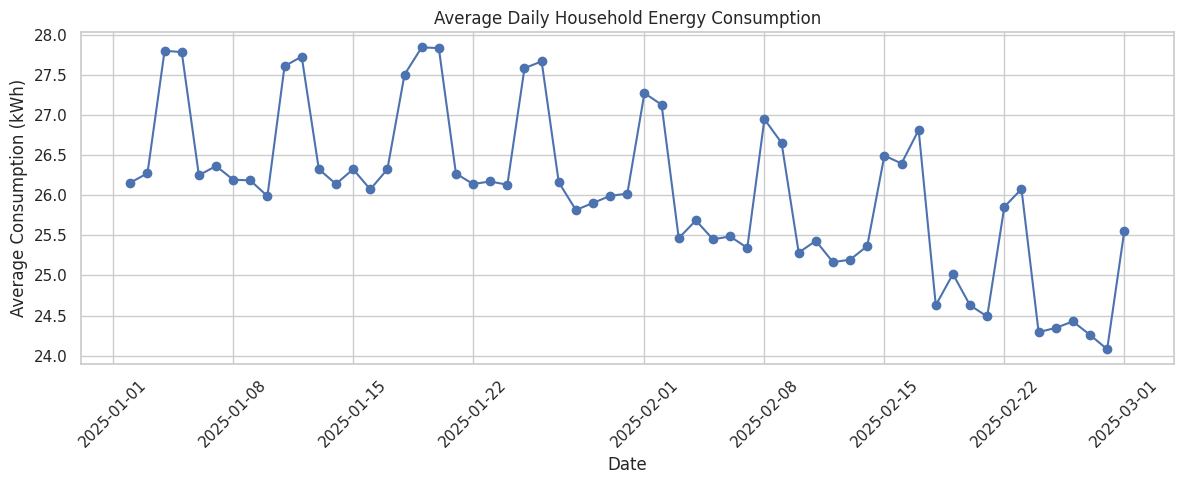

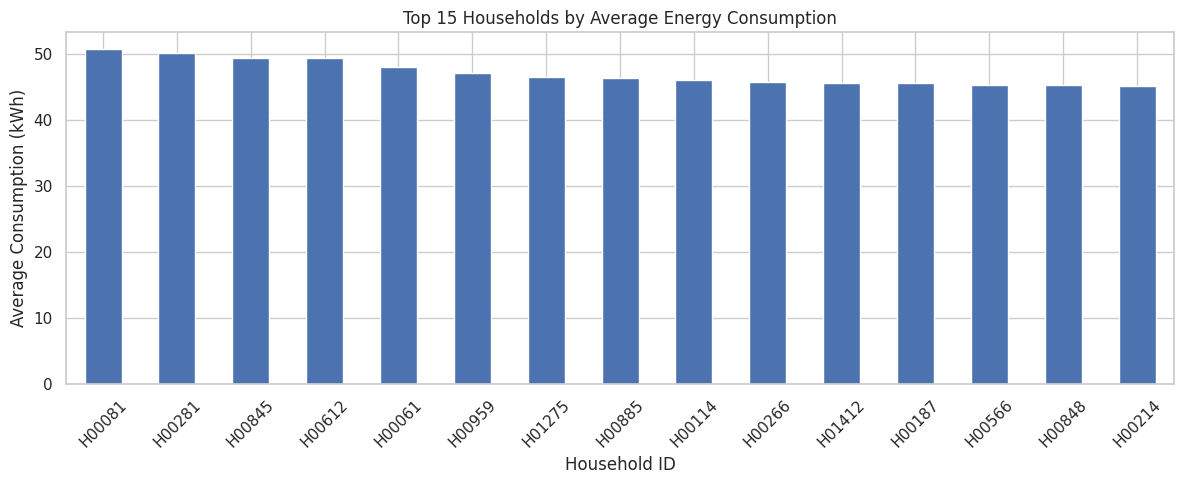

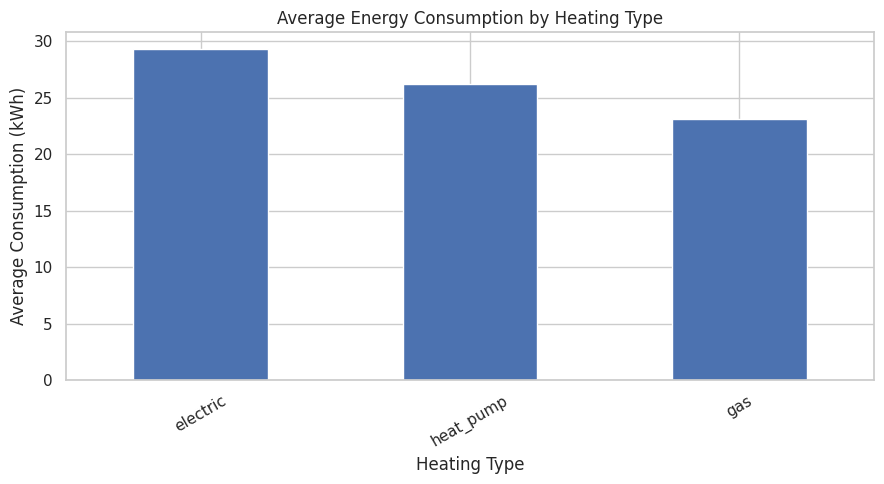

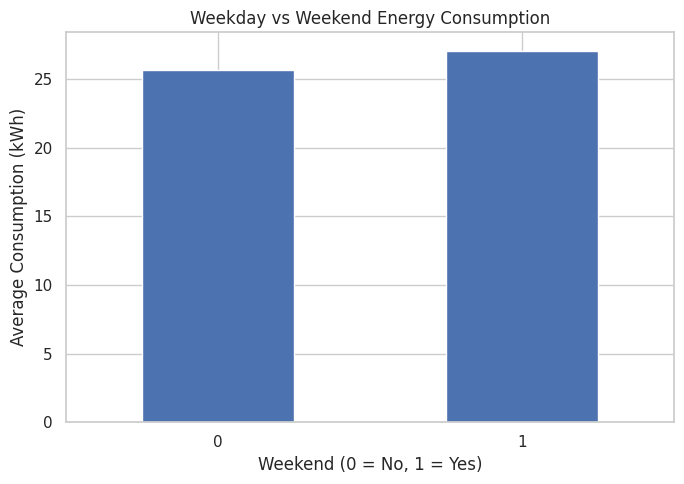

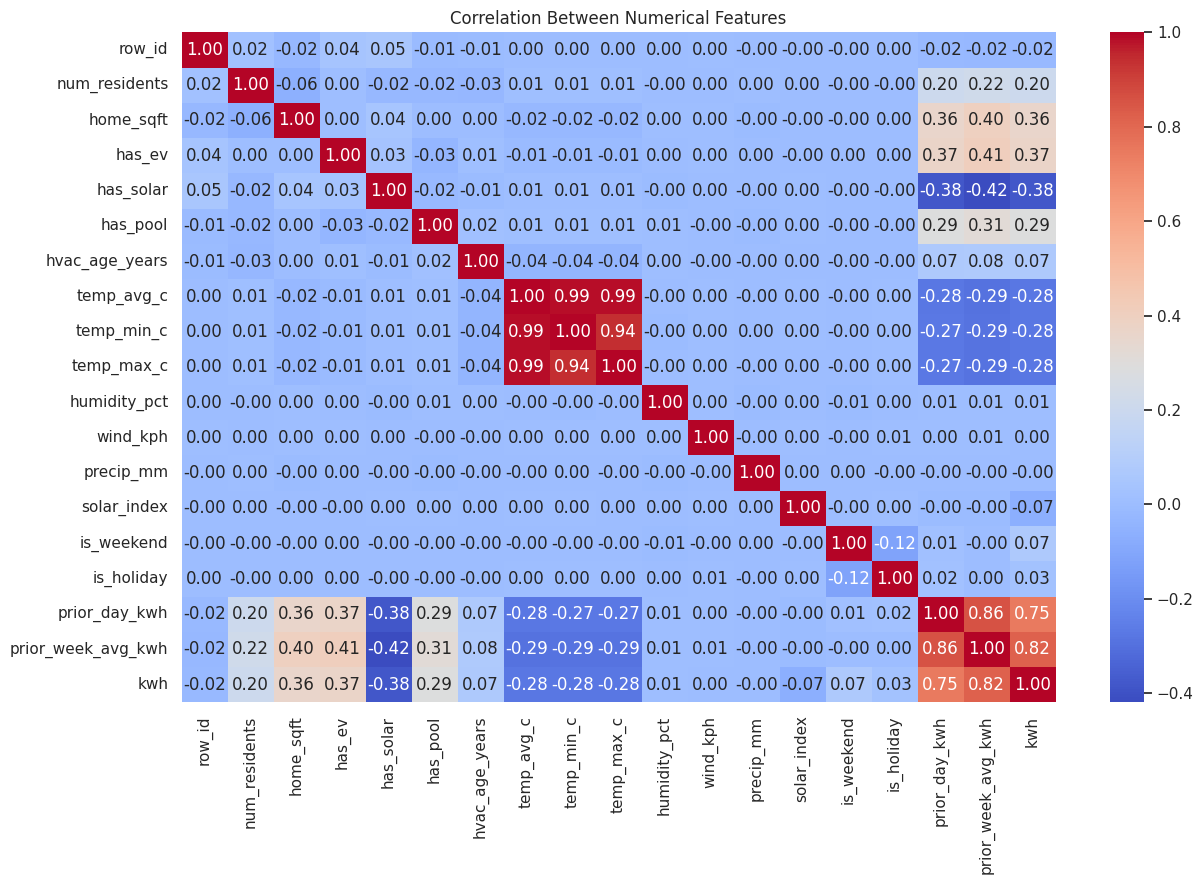


========== ANALYTICAL INSIGHTS ==========
Total records: 88500
Unique households: 1500
Average consumption: 26.064 kWh
Maximum consumption: 76.2 kWh
Minimum consumption: 0.4 kWh
Total recorded consumption: 2306706.75 kWh

Highest consumption date:
2025-01-19 00:00:00 27.842 kWh average

Lowest consumption date:
2025-02-28 00:00:00 24.081 kWh average

Consumption by heating type:
heating_type
electric     29.306
heat_pump    26.205
gas          23.078
Name: kwh, dtype: float64

Charts saved in /content/greengrid_charts/


In [ ]:

# ============================================================
# GREENGRID - STEP 4
# DATA ANALYTICS AND VISUALIZATION
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("/content/greengrid_charts", exist_ok=True)

# Load dataset
file_path = "/content/clean_train.csv"

if not os.path.exists(file_path):
    file_path = "/content/train.csv"

df = pd.read_csv(file_path)

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["kwh"] = pd.to_numeric(df["kwh"], errors="coerce")
df = df.dropna(subset=["date", "kwh"])

sns.set_theme(style="whitegrid")

print("DATASET SHAPE:", df.shape)
print("\nDESCRIPTIVE STATISTICS:")
print(df["kwh"].describe())

# ------------------------------------------------------------
# 1. DAILY ENERGY CONSUMPTION
# ------------------------------------------------------------

daily = df.groupby("date")["kwh"].mean()

plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily.values, marker="o")
plt.title("Average Daily Household Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Average Consumption (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("/content/greengrid_charts/daily_consumption.png")
plt.show()

# ------------------------------------------------------------
# 2. TOP 15 HOUSEHOLDS BY AVERAGE CONSUMPTION
# ------------------------------------------------------------

household = (
    df.groupby("household_id")["kwh"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 5))
household.plot(kind="bar")
plt.title("Top 15 Households by Average Energy Consumption")
plt.xlabel("Household ID")
plt.ylabel("Average Consumption (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("/content/greengrid_charts/household_consumption.png")
plt.show()

# ------------------------------------------------------------
# 3. CONSUMPTION BY HEATING TYPE
# ------------------------------------------------------------

if "heating_type" in df.columns:

    heating = df.groupby("heating_type")["kwh"].mean().sort_values(
        ascending=False
    )

    plt.figure(figsize=(9, 5))
    heating.plot(kind="bar")
    plt.title("Average Energy Consumption by Heating Type")
    plt.xlabel("Heating Type")
    plt.ylabel("Average Consumption (kWh)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.savefig("/content/greengrid_charts/heating_consumption.png")
    plt.show()

# ------------------------------------------------------------
# 4. WEEKDAY VS WEEKEND
# ------------------------------------------------------------

if "is_weekend" in df.columns:

    weekend = df.groupby("is_weekend")["kwh"].mean()

    plt.figure(figsize=(7, 5))
    weekend.plot(kind="bar")
    plt.title("Weekday vs Weekend Energy Consumption")
    plt.xlabel("Weekend (0 = No, 1 = Yes)")
    plt.ylabel("Average Consumption (kWh)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig("/content/greengrid_charts/weekend_consumption.png")
    plt.show()

# ------------------------------------------------------------
# 5. WEATHER VS ENERGY CONSUMPTION
# ------------------------------------------------------------

temperature_col = next(
    (c for c in df.columns if "temperature" in c.lower()),
    None
)

if temperature_col:

    plt.figure(figsize=(9, 5))
    plt.scatter(df[temperature_col], df["kwh"], alpha=0.25)
    plt.title("Temperature vs Household Energy Consumption")
    plt.xlabel(temperature_col)
    plt.ylabel("Energy Consumption (kWh)")
    plt.tight_layout()
    plt.savefig("/content/greengrid_charts/temperature_consumption.png")
    plt.show()

# ------------------------------------------------------------
# 6. NUMERICAL CORRELATION
# ------------------------------------------------------------

numeric = df.select_dtypes(include=np.number)
correlation = numeric.corr()

plt.figure(figsize=(13, 9))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.savefig("/content/greengrid_charts/correlation_heatmap.png")
plt.show()

# ------------------------------------------------------------
# 7. IMPORTANT ANALYTICAL RESULTS
# ------------------------------------------------------------

print("\n========== ANALYTICAL INSIGHTS ==========")

print("Total records:", len(df))
print("Unique households:", df["household_id"].nunique())
print("Average consumption:", round(df["kwh"].mean(), 3), "kWh")
print("Maximum consumption:", round(df["kwh"].max(), 3), "kWh")
print("Minimum consumption:", round(df["kwh"].min(), 3), "kWh")
print("Total recorded consumption:", round(df["kwh"].sum(), 3), "kWh")

print("\nHighest consumption date:")
print(daily.idxmax(), round(daily.max(), 3), "kWh average")

print("\nLowest consumption date:")
print(daily.idxmin(), round(daily.min(), 3), "kWh average")

if "heating_type" in df.columns:
    print("\nConsumption by heating type:")
    print(heating.round(3))

print("\nCharts saved in /content/greengrid_charts/")


Training fast Random Forest model...

========== MODEL EVALUATION ==========
MAE  : 3.1746
RMSE : 4.3351
R2   : 0.7469


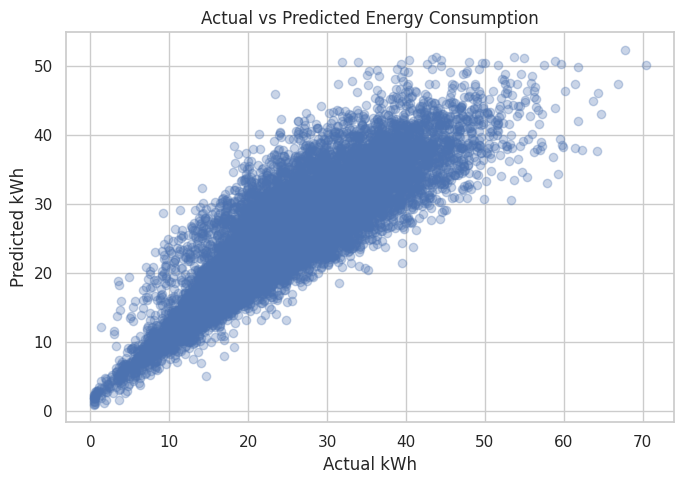


TOP 10 IMPORTANT FEATURES
           Feature  Importance
prior_week_avg_kwh    0.749594
     prior_day_kwh    0.115561
         has_solar    0.023443
       solar_index    0.022224
               day    0.011204
         home_sqft    0.010973
            has_ev    0.007272
       day_of_week    0.005974
          wind_kph    0.005845
        temp_max_c    0.005806


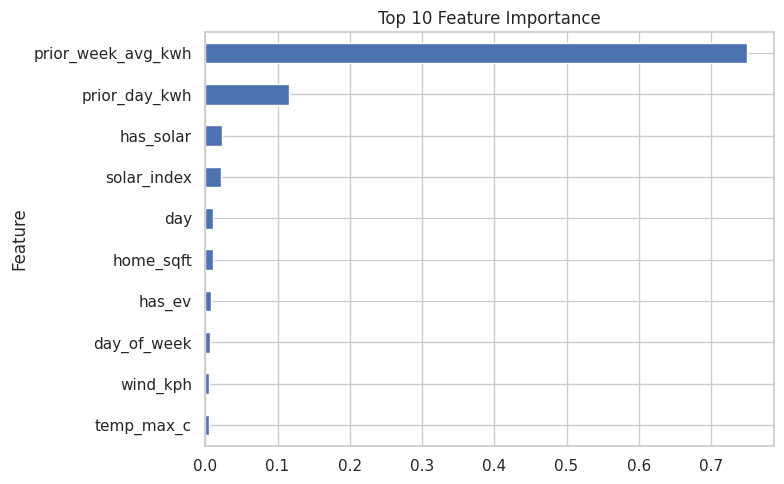


Training final model on complete dataset...

========== FINAL RESULTS ==========
Predictions generated: 21000
   row_id        kwh
0      59  26.478245
1      60  23.805255
2      61  23.690900
3      62  24.429025
4      63  24.117127
5      64  24.094787
6      65  25.413733
7      66  24.375453
8      67  23.927913
9      68  24.113210

Model saved successfully!
CSV: /content/greengrid_predictions.csv
Model: /content/greengrid_random_forest.pkl
Time taken: 192.67 seconds


In [ ]:

# ============================================================
# GREENGRID - FAST MACHINE LEARNING MODEL
# Random Forest Regression
# ============================================================

import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

start = time.time()

os.makedirs("/content/greengrid_charts", exist_ok=True)

# 1. Load datasets
train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")

# 2. Feature engineering
def prepare(data):
    data = data.copy()

    if "date" in data.columns:
        date = pd.to_datetime(data["date"], errors="coerce")
        data["month"] = date.dt.month
        data["day"] = date.dt.day
        data["day_of_week"] = date.dt.dayofweek
        data = data.drop(columns=["date"])

    data = data.drop(columns=["row_id"], errors="ignore")
    return data

X = prepare(train.drop(columns=["kwh"]))
X_test = prepare(test)

y = pd.to_numeric(train["kwh"], errors="coerce")
valid = y.notna()

X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)

X_test = X_test.reindex(columns=X.columns)

# 3. Convert categorical variables to numeric
combined = pd.concat([X, X_test], ignore_index=True)
combined = pd.get_dummies(combined, dummy_na=True)
combined = combined.replace([np.inf, -np.inf], np.nan)
combined = combined.fillna(combined.median())

X = combined.iloc[:len(X)].reset_index(drop=True)
X_test = combined.iloc[len(X):].reset_index(drop=True)

# 4. Chronological split
if "date" in train.columns:
    dates = pd.to_datetime(train.loc[valid, "date"], errors="coerce")
    order = np.argsort(dates.to_numpy())
else:
    order = np.arange(len(X))

split = int(len(order) * 0.80)

train_idx = order[:split]
val_idx = order[split:]

# 5. Train smaller Random Forest
model = RandomForestRegressor(
    n_estimators=30,
    max_depth=12,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

print("Training fast Random Forest model...")
model.fit(X.iloc[train_idx], y.iloc[train_idx])

# 6. Evaluate
pred = model.predict(X.iloc[val_idx])

mae = mean_absolute_error(y.iloc[val_idx], pred)
rmse = np.sqrt(mean_squared_error(y.iloc[val_idx], pred))
r2 = r2_score(y.iloc[val_idx], pred)

print("\n========== MODEL EVALUATION ==========")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

# 7. Actual vs Predicted graph
plt.figure(figsize=(7, 5))
plt.scatter(y.iloc[val_idx], pred, alpha=0.3)
plt.xlabel("Actual kWh")
plt.ylabel("Predicted kWh")
plt.title("Actual vs Predicted Energy Consumption")
plt.tight_layout()
plt.savefig("/content/greengrid_charts/actual_vs_predicted.png")
plt.show()

# 8. Feature importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTOP 10 IMPORTANT FEATURES")
print(importance.head(10).to_string(index=False))

importance.head(10).sort_values("Importance").plot(
    x="Feature", y="Importance",
    kind="barh", figsize=(8, 5), legend=False
)

plt.title("Top 10 Feature Importance")
plt.tight_layout()
plt.savefig("/content/greengrid_charts/feature_importance.png")
plt.show()

# 9. Final training on complete dataset
print("\nTraining final model on complete dataset...")

model.fit(X, y)

# 10. Generate predictions
test_predictions = model.predict(X_test)

submission = pd.DataFrame()

if "row_id" in test.columns:
    submission["row_id"] = test["row_id"]

submission["kwh"] = test_predictions
submission.to_csv("/content/greengrid_predictions.csv", index=False)

# 11. Save model
joblib.dump(model, "/content/greengrid_random_forest.pkl")

print("\n========== FINAL RESULTS ==========")
print("Predictions generated:", len(submission))
print(submission.head(10))

print("\nModel saved successfully!")
print("CSV: /content/greengrid_predictions.csv")
print("Model: /content/greengrid_random_forest.pkl")
print("Time taken:", round(time.time() - start, 2), "seconds")


In [ ]:

import os
import subprocess

files = [
    "/content/greengrid_predictions.csv",
    "/content/greengrid_random_forest.pkl",
    "/content/greengrid_charts/actual_vs_predicted.png",
    "/content/greengrid_charts/feature_importance.png"
]

print("MACHINE LEARNING OUTPUTS")
for f in files:
    print(("FOUND  " if os.path.exists(f) else "MISSING"), f)

print("\nHADOOP MAPREDUCE OUTPUTS")
for job in ["household", "daily", "heating"]:
    result = subprocess.run(
        ["hdfs", "dfs", "-test", "-e",
         f"/greengrid/mapreduce/output/{job}/part-00000"]
    )
    print(("FOUND  " if result.returncode == 0 else "MISSING"), job)


MACHINE LEARNING OUTPUTS
FOUND   /content/greengrid_predictions.csv
FOUND   /content/greengrid_random_forest.pkl
FOUND   /content/greengrid_charts/actual_vs_predicted.png
FOUND   /content/greengrid_charts/feature_importance.png

HADOOP MAPREDUCE OUTPUTS
MISSING household
MISSING daily
MISSING heating


GREENGRID PROJECT - PRESENTATION DATA COLLECTION

1. DATASET INFORMATION
--------------------------------------------------
Training shape: (88500, 22)
Testing shape: (21000, 21)
Training columns: ['row_id', 'household_id', 'date', 'num_residents', 'home_sqft', 'has_ev', 'has_solar', 'has_pool', 'heating_type', 'hvac_age_years', 'temp_avg_c', 'temp_min_c', 'temp_max_c', 'humidity_pct', 'wind_kph', 'precip_mm', 'solar_index', 'is_weekend', 'is_holiday', 'prior_day_kwh', 'prior_week_avg_kwh', 'kwh']
Testing columns: ['row_id', 'household_id', 'date', 'num_residents', 'home_sqft', 'has_ev', 'has_solar', 'has_pool', 'heating_type', 'hvac_age_years', 'temp_avg_c', 'temp_min_c', 'temp_max_c', 'humidity_pct', 'wind_kph', 'precip_mm', 'solar_index', 'is_weekend', 'is_holiday', 'prior_day_kwh', 'prior_week_avg_kwh']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88500 entries, 0 to 88499
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------            

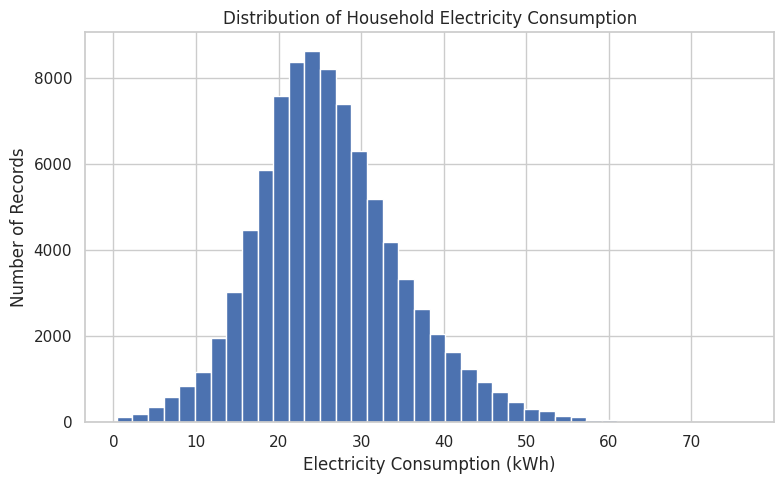


4. TIME-BASED ANALYSIS
--------------------------------------------------
Date range: 2025-01-02 00:00:00 to 2025-03-01 00:00:00

Daily consumption summary:
            mean           sum
count  59.000000     59.000000
mean   26.064483  39096.724576
std     1.002336   1503.504046
min    24.081080  36121.620000
25%    25.441397  38162.095000
50%    26.140133  39210.200000
75%    26.444960  39667.440000
max    27.842133  41763.200000


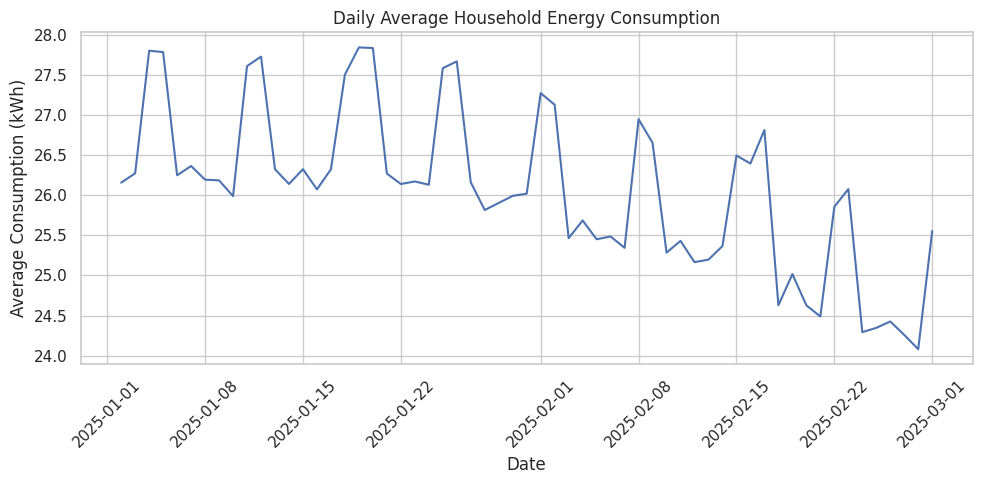


5. HOUSEHOLD ANALYSIS
--------------------------------------------------
Unique households: 1500

Top 10 households:
household_id      mean     sum  count
      H00081 50.742373 2993.80     59
      H00281 50.147458 2958.70     59
      H00845 49.376780 2913.23     59
      H00612 49.365763 2912.58     59
      H00061 48.105932 2838.25     59
      H00959 47.184068 2783.86     59
      H01275 46.507797 2743.96     59
      H00885 46.409831 2738.18     59
      H00114 45.998305 2713.90     59
      H00266 45.784407 2701.28     59


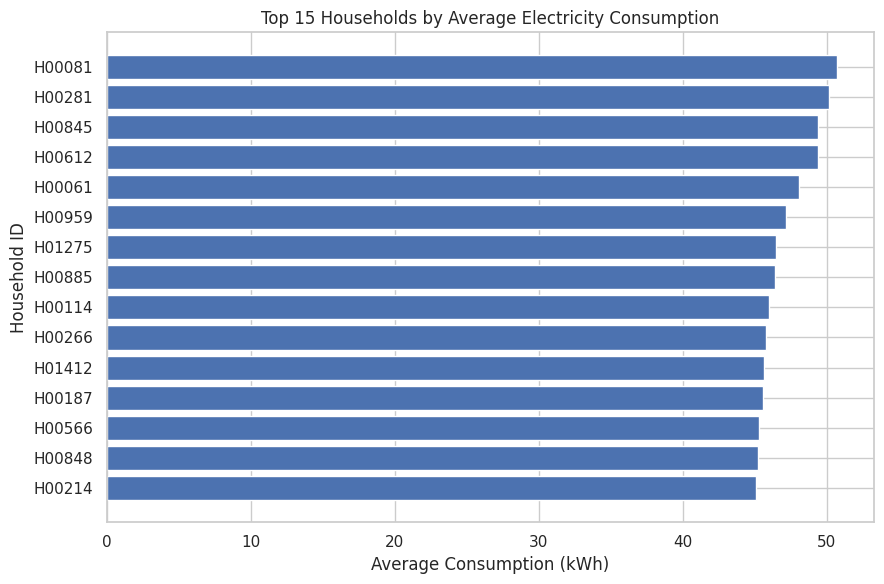


6. HEATING TYPE ANALYSIS
--------------------------------------------------
heating_type      mean       sum  count
    electric 29.306308 907762.90  30975
   heat_pump 26.204841 598335.14  22833
         gas 23.077618 800608.71  34692


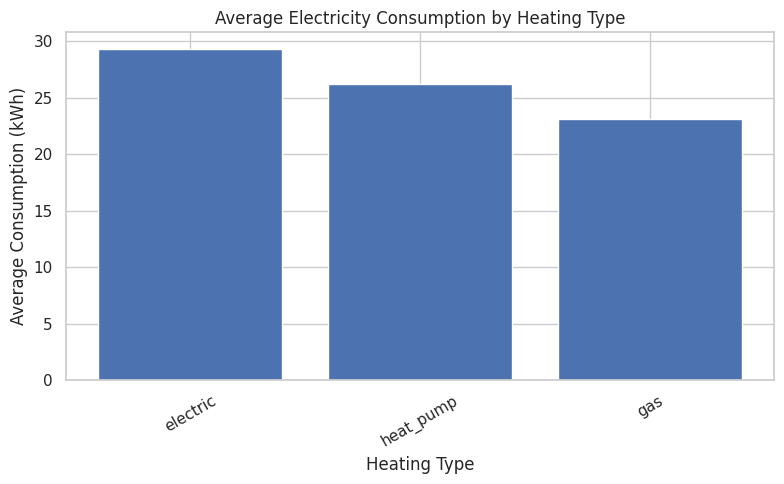


7. WEEKEND AND WEEKDAY ANALYSIS
--------------------------------------------------
 is_weekend       kwh
          0 25.664448
          1 27.052805


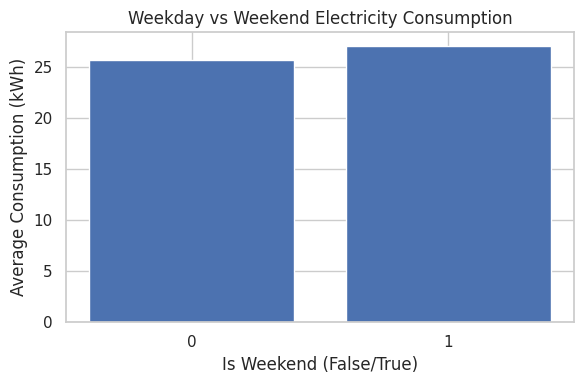


8. CORRELATION ANALYSIS
--------------------------------------------------
Features most correlated with kWh:
prior_week_avg_kwh    0.819591
prior_day_kwh         0.747664
has_solar            -0.382553
has_ev                0.370560
home_sqft             0.361046
has_pool              0.285829
temp_avg_c           -0.279810
temp_max_c           -0.275961
temp_min_c           -0.275231
num_residents         0.204189
Name: kwh, dtype: float64


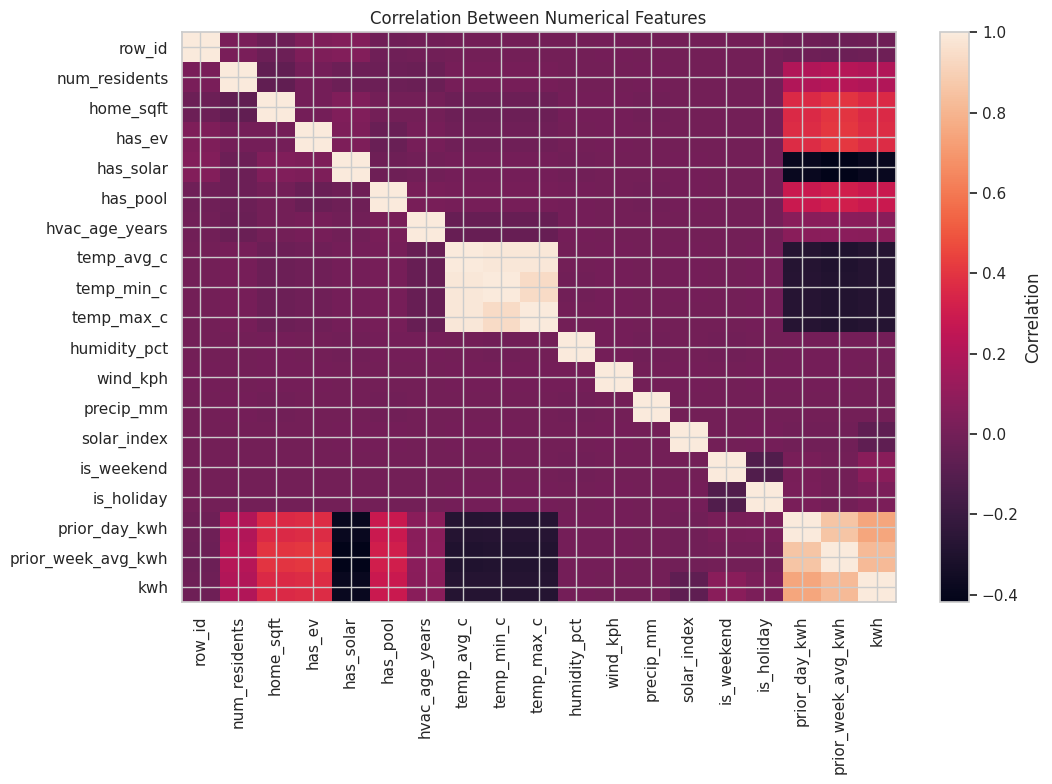


9. HADOOP INFORMATION
--------------------------------------------------
Hadoop version:
Hadoop 3.5.0
Source code repository https://github.com/apache/hadoop.git -r dbcc7cd797100e6b32cd84f85b53a5193a5f9af0
Compiled by cnauroth on 2026-03-24T16:56Z
Compiled on platform linux-x86_64
Compiled with protoc 3.25.5
From source with checksum 64582ed0a62a169c39a19c734a8f33b5
This command was run using /content/hadoop/share/hadoop/common/hadoop-common-3.5.0.jar

HDFS directory listing:
ls: Call From 3fa1e404d793/172.28.0.12 to localhost:9000 failed on connection exception: java.net.ConnectException: Connection refused; For more details see:  http://wiki.apache.org/hadoop/ConnectionRefused

10. MAPREDUCE RESULTS
--------------------------------------------------

HOUSEHOLD JOB:
Output not found or HDFS is unavailable.
cat: Call From 3fa1e404d793/172.28.0.12 to localhost:9000 failed on connection exception: java.net.ConnectException: Connection refused; For more details see:  http://wiki.apache.o

In [ ]:

# ================================================================
# GREENGRID PROJECT - COMPLETE PPT EVIDENCE GENERATOR
# Collects dataset, Hadoop, MapReduce, ML, prediction and chart data
# Does NOT train the model again.
# ================================================================

import os
import json
import shutil
import zipfile
import subprocess
import warnings
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
START = time.time()

BASE = "/content/GreenGrid_PPT_Evidence"
CHARTS = os.path.join(BASE, "Charts")
HADOOP = os.path.join(BASE, "Hadoop_Results")
DATA = os.path.join(BASE, "Dataset_Analysis")
ML = os.path.join(BASE, "Machine_Learning")

for folder in [BASE, CHARTS, HADOOP, DATA, ML]:
    os.makedirs(folder, exist_ok=True)

summary = {}
print("=" * 65)
print("GREENGRID PROJECT - PRESENTATION DATA COLLECTION")
print("=" * 65)

# ------------------------------------------------
# 1. LOAD DATASETS
# ------------------------------------------------

train_path = "/content/train.csv"
test_path = "/content/test.csv"

if not os.path.exists(train_path):
    raise FileNotFoundError("train.csv not found in /content/")
if not os.path.exists(test_path):
    raise FileNotFoundError("test.csv not found in /content/")

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print("\n1. DATASET INFORMATION")
print("-" * 50)

print("Training shape:", train.shape)
print("Testing shape:", test.shape)
print("Training columns:", list(train.columns))
print("Testing columns:", list(test.columns))

summary["dataset"] = {
    "training_rows": int(train.shape[0]),
    "training_columns": int(train.shape[1]),
    "testing_rows": int(test.shape[0]),
    "testing_columns": int(test.shape[1]),
    "training_column_names": list(train.columns),
    "testing_column_names": list(test.columns)
}

# Save dataset information
with open(os.path.join(DATA, "dataset_columns.txt"), "w") as f:
    f.write("TRAINING DATASET\n")
    f.write(str(train.info()))
    f.write("\n\nCOLUMNS:\n")
    f.write(str(train.columns.tolist()))

# ------------------------------------------------
# 2. DATA QUALITY
# ------------------------------------------------

print("\n2. DATA QUALITY ANALYSIS")
print("-" * 50)

quality = pd.DataFrame({
    "Column": train.columns,
    "Data Type": train.dtypes.astype(str).values,
    "Missing Values": train.isnull().sum().values,
    "Missing Percentage": (
        train.isnull().mean().values * 100
    ).round(2),
    "Unique Values": train.nunique().values
})

print(quality.to_string(index=False))
quality.to_csv(os.path.join(DATA, "data_quality.csv"), index=False)

summary["data_quality"] = {
    "training_missing_cells": int(train.isnull().sum().sum()),
    "testing_missing_cells": int(test.isnull().sum().sum()),
    "duplicate_training_rows": int(train.duplicated().sum()),
    "duplicate_testing_rows": int(test.duplicated().sum())
}

# ------------------------------------------------
# 3. TARGET VARIABLE ANALYSIS
# ------------------------------------------------

print("\n3. ELECTRICITY CONSUMPTION ANALYSIS")
print("-" * 50)

if "kwh" in train.columns:
    train["kwh"] = pd.to_numeric(train["kwh"], errors="coerce")
    target = train["kwh"].dropna()

    target_stats = {
        "count": int(target.count()),
        "mean_kwh": float(target.mean()),
        "median_kwh": float(target.median()),
        "minimum_kwh": float(target.min()),
        "maximum_kwh": float(target.max()),
        "standard_deviation": float(target.std()),
        "total_kwh": float(target.sum())
    }

    summary["target_statistics"] = target_stats
    print(pd.Series(target_stats))

    target.describe().to_csv(
        os.path.join(DATA, "target_statistics.csv")
    )

    plt.figure(figsize=(8, 5))
    plt.hist(target, bins=40)
    plt.xlabel("Electricity Consumption (kWh)")
    plt.ylabel("Number of Records")
    plt.title("Distribution of Household Electricity Consumption")
    plt.tight_layout()
    plt.savefig(os.path.join(CHARTS, "consumption_distribution.png"))
    plt.show()

# ------------------------------------------------
# 4. DATE AND CONSUMPTION ANALYSIS
# ------------------------------------------------

print("\n4. TIME-BASED ANALYSIS")
print("-" * 50)

if "date" in train.columns and "kwh" in train.columns:

    train["date"] = pd.to_datetime(train["date"], errors="coerce")

    daily = (
        train.dropna(subset=["date", "kwh"])
        .groupby("date")["kwh"]
        .agg(["mean", "sum", "count"])
        .reset_index()
    )

    daily.to_csv(os.path.join(DATA, "daily_consumption.csv"), index=False)

    print("Date range:",
          train["date"].min(), "to", train["date"].max())
    print("\nDaily consumption summary:")
    print(daily[["mean", "sum"]].describe())

    plt.figure(figsize=(10, 5))
    plt.plot(daily["date"], daily["mean"])
    plt.xlabel("Date")
    plt.ylabel("Average Consumption (kWh)")
    plt.title("Daily Average Household Energy Consumption")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(os.path.join(CHARTS, "daily_consumption.png"))
    plt.show()

    summary["date_analysis"] = {
        "start_date": str(train["date"].min()),
        "end_date": str(train["date"].max()),
        "number_of_days": int(train["date"].nunique()),
        "highest_average_day": str(
            daily.loc[daily["mean"].idxmax(), "date"]
        ),
        "highest_average_kwh": float(daily["mean"].max()),
        "lowest_average_day": str(
            daily.loc[daily["mean"].idxmin(), "date"]
        ),
        "lowest_average_kwh": float(daily["mean"].min())
    }

# ------------------------------------------------
# 5. HOUSEHOLD ANALYSIS
# ------------------------------------------------

print("\n5. HOUSEHOLD ANALYSIS")
print("-" * 50)

if "household_id" in train.columns and "kwh" in train.columns:

    household = (
        train.groupby("household_id")["kwh"]
        .agg(["mean", "sum", "count"])
        .reset_index()
        .sort_values("mean", ascending=False)
    )

    household.to_csv(
        os.path.join(DATA, "household_consumption.csv"),
        index=False
    )

    print("Unique households:", train["household_id"].nunique())
    print("\nTop 10 households:")
    print(household.head(10).to_string(index=False))

    top = household.head(15).sort_values("mean")

    plt.figure(figsize=(9, 6))
    plt.barh(top["household_id"].astype(str), top["mean"])
    plt.xlabel("Average Consumption (kWh)")
    plt.ylabel("Household ID")
    plt.title("Top 15 Households by Average Electricity Consumption")
    plt.tight_layout()
    plt.savefig(os.path.join(CHARTS, "household_consumption.png"))
    plt.show()

    summary["households"] = {
        "unique_households": int(train["household_id"].nunique()),
        "highest_average_household": str(
            household.iloc[0]["household_id"]
        ),
        "highest_average_kwh": float(household.iloc[0]["mean"])
    }

# ------------------------------------------------
# 6. HEATING TYPE ANALYSIS
# ------------------------------------------------

print("\n6. HEATING TYPE ANALYSIS")
print("-" * 50)

if "heating_type" in train.columns and "kwh" in train.columns:

    heating = (
        train.groupby("heating_type")["kwh"]
        .agg(["mean", "sum", "count"])
        .reset_index()
        .sort_values("mean", ascending=False)
    )

    heating.to_csv(
        os.path.join(DATA, "heating_type_analysis.csv"),
        index=False
    )

    print(heating.to_string(index=False))

    plt.figure(figsize=(8, 5))
    plt.bar(heating["heating_type"].astype(str), heating["mean"])
    plt.xlabel("Heating Type")
    plt.ylabel("Average Consumption (kWh)")
    plt.title("Average Electricity Consumption by Heating Type")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.savefig(os.path.join(CHARTS, "heating_type.png"))
    plt.show()

    summary["heating_analysis"] = heating.to_dict(orient="records")

# ------------------------------------------------
# 7. WEEKEND VS WEEKDAY
# ------------------------------------------------

print("\n7. WEEKEND AND WEEKDAY ANALYSIS")
print("-" * 50)

if "is_weekend" in train.columns and "kwh" in train.columns:

    weekend = (
        train.groupby("is_weekend")["kwh"]
        .mean()
        .reset_index()
    )

    print(weekend.to_string(index=False))

    weekend.to_csv(
        os.path.join(DATA, "weekend_analysis.csv"),
        index=False
    )

    plt.figure(figsize=(6, 4))
    plt.bar(
        weekend["is_weekend"].astype(str),
        weekend["kwh"]
    )
    plt.xlabel("Is Weekend (False/True)")
    plt.ylabel("Average Consumption (kWh)")
    plt.title("Weekday vs Weekend Electricity Consumption")
    plt.tight_layout()
    plt.savefig(os.path.join(CHARTS, "weekend_analysis.png"))
    plt.show()

# ------------------------------------------------
# 8. CORRELATION ANALYSIS
# ------------------------------------------------

print("\n8. CORRELATION ANALYSIS")
print("-" * 50)

numeric = train.select_dtypes(include=np.number)
correlation = numeric.corr()

correlation.to_csv(
    os.path.join(DATA, "correlation_matrix.csv")
)

if "kwh" in correlation.columns:
    target_corr = (
        correlation["kwh"]
        .drop("kwh")
        .sort_values(key=abs, ascending=False)
    )

    print("Features most correlated with kWh:")
    print(target_corr.head(10))

    summary["top_correlations_with_kwh"] = {
        str(k): float(v) for k, v in target_corr.head(10).items()
    }

plt.figure(figsize=(11, 8))
plt.imshow(correlation, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)),
           correlation.columns)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.savefig(os.path.join(CHARTS, "correlation_heatmap.png"))
plt.show()

# ------------------------------------------------
# 9. HADOOP INFORMATION
# ------------------------------------------------

print("\n9. HADOOP INFORMATION")
print("-" * 50)

def run_command(command):
    try:
        result = subprocess.run(
            command,
            capture_output=True,
            text=True,
            timeout=30
        )
        return result.stdout.strip(), result.stderr.strip(), result.returncode
    except Exception as e:
        return "", str(e), 1

hadoop_version, hadoop_error, hadoop_status = run_command(
    ["hadoop", "version"]
)

print("Hadoop version:")
print(hadoop_version[:500] if hadoop_version else hadoop_error)

summary["hadoop"] = {
    "version_output": hadoop_version[:500],
    "version_command_success": hadoop_status == 0,
    "execution_environment": "Google Colab single-node environment"
}

hdfs_listing, hdfs_error, hdfs_status = run_command(
    ["hdfs", "dfs", "-ls", "-R", "/greengrid"]
)

print("\nHDFS directory listing:")
print(hdfs_listing if hdfs_listing else hdfs_error)

with open(os.path.join(HADOOP, "hdfs_directory_listing.txt"), "w") as f:
    f.write(hdfs_listing or hdfs_error)

# ------------------------------------------------
# 10. COLLECT MAPREDUCE RESULTS
# ------------------------------------------------

print("\n10. MAPREDUCE RESULTS")
print("-" * 50)

mapreduce_jobs = ["household", "daily", "heating"]
mapreduce_status = {}

for job in mapreduce_jobs:

    hdfs_path = f"/greengrid/mapreduce/output/{job}/part-00000"

    content, error, status = run_command(
        ["hdfs", "dfs", "-cat", hdfs_path]
    )

    mapreduce_status[job] = status == 0

    print(f"\n{job.upper()} JOB:")

    if status == 0 and content:
        print("\n".join(content.splitlines()[:10]))

        with open(
            os.path.join(HADOOP, f"{job}_mapreduce_output.txt"),
            "w"
        ) as f:
            f.write(content)

        try:
            result_df = pd.read_csv(
                pd.io.common.StringIO(content),
                sep="\t",
                header=None
            )
            result_df.to_csv(
                os.path.join(HADOOP, f"{job}_mapreduce_output.csv"),
                index=False
            )
        except Exception as e:
            print("Could not convert output to CSV:", e)

    else:
        print("Output not found or HDFS is unavailable.")
        print(error[:300])

summary["mapreduce_jobs"] = mapreduce_status

# ------------------------------------------------
# 11. MACHINE LEARNING RESULTS
# ------------------------------------------------

print("\n11. MACHINE LEARNING RESULTS")
print("-" * 50)

metrics = {}

# Reuse evaluation variables from your previous ML cell
for name in ["mae", "rmse", "r2"]:
    if name in globals():
        try:
            metrics[name.upper()] = float(globals()[name])
        except Exception:
            pass

if metrics:
    print("Previously calculated model metrics:")
    for key, value in metrics.items():
        print(f"{key}: {value:.5f}")
else:
    print("MAE/RMSE/R2 variables not found in current runtime.")
    print("Do not worry: the saved model and predictions are checked separately.")

summary["model_metrics"] = metrics

# Collect prediction CSV
prediction_path = "/content/greengrid_predictions.csv"

if os.path.exists(prediction_path):

    predictions = pd.read_csv(prediction_path)

    print("\nPrediction dataset shape:", predictions.shape)
    print("\nFirst 10 predictions:")
    print(predictions.head(10).to_string(index=False))

    predictions.to_csv(
        os.path.join(ML, "test_predictions.csv"),
        index=False
    )

    if "kwh" in predictions.columns:
        prediction_stats = predictions["kwh"].describe().to_dict()

        summary["prediction_statistics"] = {
            str(k): float(v) for k, v in prediction_stats.items()
        }

        print("\nPrediction statistics:")
        print(predictions["kwh"].describe())

else:
    print("Prediction CSV not found.")

# ------------------------------------------------
# 12. FEATURE IMPORTANCE
# ------------------------------------------------

print("\n12. FEATURE IMPORTANCE")
print("-" * 50)

if "importance_df" in globals():
    try:
        feature_importance = globals()["importance_df"].copy()
        feature_importance.to_csv(
            os.path.join(ML, "feature_importance.csv"),
            index=False
        )
        print(feature_importance.head(15).to_string(index=False))
        summary["feature_importance"] = (
            feature_importance.head(15).to_dict(orient="records")
        )
    except Exception as e:
        print("Could not reuse importance_df:", e)

else:
    # Try to load the saved fast Random Forest model
    model_path = "/content/greengrid_random_forest.pkl"

    if os.path.exists(model_path):
        try:
            import joblib

            saved_model = joblib.load(model_path)

            # Recreate the exact feature matrix used by the fast model
            def prepare_for_importance(data):
                data = data.copy()
                if "date" in data.columns:
                    dt = pd.to_datetime(data["date"], errors="coerce")
                    data["month"] = dt.dt.month
                    data["day"] = dt.dt.day
                    data["day_of_week"] = dt.dt.dayofweek
                    data = data.drop(columns=["date"])
                return data.drop(columns=["row_id"], errors="ignore")

            X_original = prepare_for_importance(
                train.drop(columns=["kwh"])
            )
            X_test_original = prepare_for_importance(test)

            combined = pd.concat(
                [X_original, X_test_original],
                ignore_index=True
            )
            combined = pd.get_dummies(combined, dummy_na=True)
            combined = combined.replace([np.inf, -np.inf], np.nan)
            combined = combined.fillna(combined.median())

            feature_names = combined.columns

            if len(feature_names) == len(saved_model.feature_importances_):
                feature_importance = pd.DataFrame({
                    "Feature": feature_names,
                    "Importance": saved_model.feature_importances_
                }).sort_values("Importance", ascending=False)

                feature_importance.to_csv(
                    os.path.join(ML, "feature_importance.csv"),
                    index=False
                )

                print(feature_importance.head(15).to_string(index=False))

                summary["feature_importance"] = (
                    feature_importance.head(15).to_dict(orient="records")
                )
            else:
                print("Model loaded, but feature names could not be matched.")

        except Exception as e:
            print("Could not inspect saved model:", str(e))
    else:
        print("Saved model not found.")

# ------------------------------------------------
# 13. CHECK MODEL FILE
# ------------------------------------------------

model_path = "/content/greengrid_random_forest.pkl"

if os.path.exists(model_path):
    print("\nSaved model found.")
    shutil.copy2(model_path, ML)
    summary["saved_model_available"] = True
else:
    print("\nSaved model not found.")
    summary["saved_model_available"] = False

# ------------------------------------------------
# 14. SAVE SUMMARY AND PRESENTATION NOTES
# ------------------------------------------------

summary_path = os.path.join(BASE, "project_summary.json")

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4, default=str)

# Automatically generate project notes
notes = f"""
# GREENGRID PROJECT - PRESENTATION NOTES

## Project Title
GreenGrid: Daily Household Energy Consumption Analysis and Forecasting

## Dataset
Training records: {train.shape[0]}
Training features/columns: {train.shape[1]}
Testing records: {test.shape[0]}
Testing features/columns: {test.shape[1]}

## Data Quality
Missing cells in training data: {train.isnull().sum().sum()}
Missing cells in testing data: {test.isnull().sum().sum()}
Duplicate training records: {train.duplicated().sum()}

## Energy Consumption
{summary.get('target_statistics', 'Target statistics unavailable')}

## Household Information
{summary.get('households', 'Household analysis unavailable')}

## Date Analysis
{summary.get('date_analysis', 'Date analysis unavailable')}

## Heating Type Analysis
{summary.get('heating_analysis', 'Heating analysis unavailable')}

## Hadoop
Hadoop environment: Google Colab single-node environment.
MapReduce jobs: Household average, daily average, heating-type average.

MapReduce job status:
{summary.get('mapreduce_jobs', {})}

## Machine Learning
Algorithm: Random Forest Regression.

Evaluation metrics:
{summary.get('model_metrics', {})}

## Predictions
{summary.get('prediction_statistics', 'Prediction statistics unavailable')}

## Important Features
{summary.get('feature_importance', 'Feature importance unavailable')}

## Conclusion
The project combines Hadoop-based data processing, exploratory
data analysis and Random Forest regression to study and predict
household electricity consumption.

IMPORTANT:
Use only the actual calculated values in your final presentation.
Do not claim that missing Hadoop jobs or model metrics were completed.
"""

with open(os.path.join(BASE, "PPT_Presentation_Notes.txt"), "w") as f:
    f.write(notes)

# ------------------------------------------------
# 15. COPY ORIGINAL DATASETS
# ------------------------------------------------

shutil.copy2(train_path, DATA)
shutil.copy2(test_path, DATA)

# ------------------------------------------------
# 16. CREATE ZIP FILE
# ------------------------------------------------

zip_path = "/content/GreenGrid_PPT_Evidence.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(BASE):
        for filename in files:
            filepath = os.path.join(root, filename)
            arcname = os.path.relpath(filepath, BASE)
            z.write(filepath, arcname)

# ------------------------------------------------
# 17. FINAL STATUS
# ------------------------------------------------

print("\n" + "=" * 65)
print("PROJECT EVIDENCE COLLECTION COMPLETED")
print("=" * 65)

print("\nPROJECT SUMMARY")
print(json.dumps(summary, indent=2, default=str))

print("\nGENERATED FILES:")
for root, dirs, files in os.walk(BASE):
    for filename in files:
        print(os.path.relpath(os.path.join(root, filename), BASE))

print("\nZIP FILE:", zip_path)
print("ZIP SIZE:", round(os.path.getsize(zip_path) / (1024*1024), 2), "MB")
print("TOTAL TIME:", round(time.time() - START, 2), "seconds")

print("\nDownload your evidence package using the next cell.")
